# 🅿️ Prática 3 — Autômatos Finitos na Prática
## Projeto de Entrega: Validador & Scanner do domínio **Estacionamento Inteligente**

**Disciplina:** Compiladores — Ciência da Computação (8º semestre) · Prof. Hercules Ramos

**Integrantes do grupo:**

1. Lucas de Almeida Lima — RA 2421495
2. Yago Feitosa Kawauchi — RA 3227980
3. Isaías Inocêncio dos Santos — RA 2407953

---

### Mapa do notebook (requisito → célula)

| Requisito | O que é | Célula |
|---|---|---|
| R1 | Dois validadores (AFD): **placa** (Mercosul + antiga) e **horário HH:MM** | 2, 3 |
| R2 | Rastreamento passo a passo (aceita × rejeita) | 2, 3 |
| R3 | Bateria de testes AFD × RegEx (0 divergências) | 4 |
| R4 | Máquina de estados de negócio: a **cancela** | 5 |
| R5 | Mini-scanner da linguagem de comandos do estacionamento | 6, 7 |
| R6 | Interface (ipywidgets) para validadores **e** scanner | 8 |
| Bônus | AFD mínimo · desenho com Graphviz · scanner por tabela · tudo conectado | 9 a 12 |
| — | Autoavaliação dos requisitos | 13 |

**Como rodar:** abra no Google Colab (ou VS Code + Jupyter) e use *Ambiente de execução → Executar tudo*.
Só usamos a biblioteca padrão do Python; a única coisa extra é o `ipywidgets` do painel (já vem no Colab).

In [1]:
# ⚙️ CÉLULA 0 — Preparação do ambiente
# Tudo nesta prática usa só a biblioteca padrão do Python.
import os
import re
import shutil
import subprocess
from itertools import product

from IPython.display import display, Image

print("✅ Ambiente pronto! Vamos construir os autômatos do estacionamento.")

✅ Ambiente pronto! Vamos construir os autômatos do estacionamento.


## 🧰 O "motor" reutilizável: a classe `AFD`

Um AFD é a 5-upla **M = (Q, Σ, δ, q0, F)**. O motor (começar em q0, seguir as setas, conferir se
terminou em F) é sempre o mesmo; **o que muda de um problema para outro é só a tabela δ**.
Por isso escrevemos o motor uma única vez.

| Definição formal | Na classe `AFD` |
|---|---|
| Q | `self.estados` (calculado a partir de `delta`) |
| Σ | `self.alfabeto` (as classes usadas no `delta`) |
| δ | `self.delta` — dicionário `(estado, classe) → próximo` |
| q0 | `self.inicial` |
| F | `self.finais` |
| caractere → classe | `self.classificar` |

Além de `rodar()` (passo a passo) e `tabela()`, a classe tem os métodos dos bônus:
`minimizar()` (AFD mínimo) e `para_dot()` (desenho automático com Graphviz).

In [2]:
# 🧰 CÉLULA 1 — Classe AFD (motor reutilizável)
class AFD:
    def __init__(self, nome, delta, inicial, finais, classificar):
        self.nome = nome
        self.delta = dict(delta)            # δ: {(estado, classe): próximo_estado}
        self.inicial = inicial              # q0
        self.finais = set(finais)           # F
        self.classificar = classificar      # função: caractere -> classe (Σ)
        # Q: estados na ordem em que aparecem; Σ: classes em ordem alfabética
        ordem = [inicial]
        for (q, _), p in self.delta.items():
            for estado in (q, p):
                if estado not in ordem:
                    ordem.append(estado)
        self.estados = ordem
        self.alfabeto = sorted({s for _, s in self.delta})

    # ---------- R2: rodar passo a passo ----------
    def rodar(self, palavra, mostrar=True):
        estado = self.inicial
        larg = max(len(q) for q in self.estados) + 2
        if mostrar:
            print(f"🔎 {self.nome} lendo {palavra!r}")
            print(f"   {'passo':5} {'lido':6} {'classe':7} {'de':{larg}} {'para'}")
        for passo, c in enumerate(palavra, start=1):
            classe = self.classificar(c)
            proximo = self.delta.get((estado, classe))
            if mostrar:
                destino = proximo if proximo is not None else "💀 morto"
                print(f"   {passo:<5} {c!r:6} {classe:7} {estado:{larg}} {destino}")
            if proximo is None:
                if mostrar:
                    print(f"   ❌ REJEITADA: não há transição de {estado} com a classe {classe!r}\n")
                return False
            estado = proximo
        aceita = estado in self.finais
        if mostrar:
            if aceita:
                print(f"   ✅ ACEITA: terminou em {estado}, que é de aceitação\n")
            else:
                print(f"   ❌ REJEITADA: terminou em {estado}, que NÃO é de aceitação\n")
        return aceita

    # ---------- R1: tabela de transição ----------
    def tabela(self):
        larg = max([len(q) for q in self.estados] + [len('estado')]) + 1
        # largura da coluna: cabe tanto o nome da classe quanto o nome de qualquer estado de destino
        col = max([len(s) for s in self.alfabeto] + [len(p) for p in self.delta.values()]) + 2
        print(f"📋 Tabela de transição — {self.nome}")
        print("     " + f"{'estado':{larg}}" + "".join(f"{s:>{col}}" for s in self.alfabeto))
        for q in self.estados:
            marca = ("→" if q == self.inicial else " ") + ("*" if q in self.finais else " ")
            linha = "".join(f"{self.delta.get((q, s), '—'):>{col}}" for s in self.alfabeto)
            print(f"  {marca} {q:{larg}}{linha}")
        print("   (→ = inicial, * = aceitação, — = vai para o estado morto)\n")

    # ---------- BÔNUS: AFD mínimo (refinamento de partições) ----------
    def minimizar(self):
        """Une estados equivalentes. Começa separando F dos demais e vai separando
        os estados cujas transições levam a grupos diferentes, até estabilizar.
        Retorna (afd_minimo, grupos_de_equivalentes, tamanho_da_partição_em_cada_rodada)."""
        MORTO = "∅"                                   # estado morto implícito (setas que faltam)
        estados = self.estados + [MORTO]

        def passo(q, s):
            return MORTO if q == MORTO else self.delta.get((q, s), MORTO)

        grupo = {q: int(q in self.finais) for q in estados}   # rodada 0: F × não-F
        rodadas = []
        while True:
            assinatura = {q: (grupo[q],) + tuple(grupo[passo(q, s)] for s in self.alfabeto)
                          for q in estados}
            numeros = {}
            novo = {q: numeros.setdefault(assinatura[q], len(numeros)) for q in estados}
            rodadas.append(len(numeros))
            if len(numeros) == len(set(grupo.values())):      # nada mais se separou: estabilizou
                break
            grupo = novo

        classes = {}
        for q in estados:
            classes.setdefault(grupo[q], []).append(q)
        mortos = set(classes[grupo[MORTO]])           # nunca chegam em F (junto com ∅)
        nome = {}
        for membros in classes.values():
            for q in membros:
                nome[q] = "=".join(membros)
        delta_min = {}
        for (q, s), p in self.delta.items():
            if q in mortos or p in mortos:
                continue
            delta_min[(nome[q], s)] = nome[p]
        minimo = AFD(self.nome + " (mínimo)", delta_min, nome[self.inicial],
                     {nome[q] for q in self.finais}, self.classificar)
        equivalentes = [m for g, m in classes.items() if len(m) > 1 and g != grupo[MORTO]]
        return minimo, equivalentes, rodadas

    # ---------- BÔNUS: desenho automático (código DOT do Graphviz) ----------
    def para_dot(self):
        arestas = {}
        for (q, s), p in self.delta.items():
            arestas.setdefault((q, p), []).append(s)
        linhas = ["digraph AFD {", "  rankdir=LR;",
                  f'  label="{self.nome}"; labelloc=t; fontsize=16;',
                  "  node [shape=circle, fontsize=11];",
                  '  inicio [shape=point, label=""];']
        for q in self.estados:
            forma = "doublecircle" if q in self.finais else "circle"
            linhas.append(f'  "{q}" [shape={forma}];')
        linhas.append(f'  inicio -> "{self.inicial}";')
        for (q, p), simbolos in arestas.items():
            rotulo = ", ".join(simbolos)
            linhas.append(f'  "{q}" -> "{p}" [label="{rotulo}"];')
        linhas.append("}")
        return "\n".join(linhas)


def desenhar(afd, arquivo):
    """Gera o PNG do AFD com o Graphviz. Se o comando `dot` não existir, mostra só o código DOT."""
    dot = afd.para_dot()
    if shutil.which("dot") is None:
        print("⚠️ Graphviz (comando 'dot') não encontrado. Cole o código abaixo em "
              "https://dreampuf.github.io/GraphvizOnline para ver o desenho:\n")
        print(dot)
        return None
    pasta = os.path.dirname(arquivo)
    if pasta:
        os.makedirs(pasta, exist_ok=True)
    with open(os.path.splitext(arquivo)[0] + ".dot", "w", encoding="utf-8") as f:
        f.write(dot)
    subprocess.run(["dot", "-Tpng", "-o", arquivo], input=dot.encode("utf-8"), check=True)
    return arquivo


print("✅ Classe AFD pronta: rodar(), tabela(), minimizar() e para_dot().")

✅ Classe AFD pronta: rodar(), tabela(), minimizar() e para_dot().


## 🚗 Validador 1 — Placa de veículo (Mercosul **e** antiga no mesmo AFD)

| Formato | Padrão | Exemplo |
|---|---|---|
| Mercosul | Letra Letra Letra **Dígito Letra Dígito Dígito** | `BRA2E19` |
| Antiga | Letra Letra Letra **-** Dígito Dígito Dígito Dígito | `ABC-1234` |

**Classes de caracteres** (para não desenhar 36 setas por estado):

| Caractere | Classe |
|---|---|
| `A` até `Z` | `L` (letra) |
| `0` até `9` | `D` (dígito) |
| `-` | `H` (hífen) |
| qualquer outro | `outro` (sem seta → estado morto) |

**O desenho** — os 3 primeiros estados são comuns; em `q3` o autômato se divide:

```
 prefixo comum:   ──► (q0) ─L─► (q1) ─L─► (q2) ─L─► (q3)

 ramo Mercosul:   (q3) ─D─► (m1) ─L─► (m2) ─D─► (m3) ─D─► ((m4))

 ramo antigo:     (q3) ─H─► (a0) ─D─► (a1) ─D─► (a2) ─D─► (a3) ─D─► ((a4))
```

São **13 estados** e dois estados de aceitação (`m4` e `a4`). A placa antiga **exige o hífen**:
`ABC1234` (sem hífen) é rejeitada. Essa é a regra de domínio que adotamos (documentada no README).

In [3]:
# 🚗 CÉLULA 2 — Validador 1: placa (Mercosul + antiga no MESMO AFD)
def classe_placa(c):
    if "A" <= c <= "Z":
        return "L"        # letra maiúscula
    if "0" <= c <= "9":
        return "D"        # dígito
    if c == "-":
        return "H"        # hífen
    return "outro"


delta_placa = {}
# prefixo comum: três letras
for de, para in [("q0", "q1"), ("q1", "q2"), ("q2", "q3")]:
    delta_placa[(de, "L")] = para
# ramo Mercosul: D L D D
delta_placa[("q3", "D")] = "m1"
delta_placa[("m1", "L")] = "m2"
delta_placa[("m2", "D")] = "m3"
delta_placa[("m3", "D")] = "m4"
# ramo antigo: - D D D D
delta_placa[("q3", "H")] = "a0"
for de, para in [("a0", "a1"), ("a1", "a2"), ("a2", "a3"), ("a3", "a4")]:
    delta_placa[(de, "D")] = para

FINAIS_PLACA = {"m4", "a4"}
placa = AFD("Placa (Mercosul + antiga)", delta_placa, "q0", FINAIS_PLACA, classe_placa)

print(f"Q = {placa.estados}   ({len(placa.estados)} estados)")
print(f"Σ = {placa.alfabeto}")
print(f"q0 = {placa.inicial!r}   F = {sorted(placa.finais)}")

Q = ['q0', 'q1', 'q2', 'q3', 'm1', 'm2', 'm3', 'm4', 'a0', 'a1', 'a2', 'a3', 'a4']   (13 estados)
Σ = ['D', 'H', 'L']
q0 = 'q0'   F = ['a4', 'm4']


In [4]:
# 📋 R1 — tabela() do validador de placa
placa.tabela()

📋 Tabela de transição — Placa (Mercosul + antiga)
     estado    D   H   L
  →  q0        —   —  q1
     q1        —   —  q2
     q2        —   —  q3
     q3       m1  a0   —
     m1        —   —  m2
     m2       m3   —   —
     m3       m4   —   —
   * m4        —   —   —
     a0       a1   —   —
     a1       a2   —   —
     a2       a3   —   —
     a3       a4   —   —
   * a4        —   —   —
   (→ = inicial, * = aceitação, — = vai para o estado morto)



In [5]:
# 🔎 R2 — rastreamento passo a passo: 2 aceitas (uma de cada ramo) e 2 jeitos de rejeitar
placa.rodar("ABC-1234")     # ✅ aceita (placa antiga)
placa.rodar("BRA2E19")      # ✅ aceita (Mercosul)
placa.rodar("BRA2019")      # ❌ MORRE NO MEIO: depois de 'BRA2' só cabe uma letra
placa.rodar("ABC-123")      # ❌ TERMINA FORA DE F: faltou um dígito

🔎 Placa (Mercosul + antiga) lendo 'ABC-1234'
   passo lido   classe  de   para
   1     'A'    L       q0   q1
   2     'B'    L       q1   q2
   3     'C'    L       q2   q3
   4     '-'    H       q3   a0
   5     '1'    D       a0   a1
   6     '2'    D       a1   a2
   7     '3'    D       a2   a3
   8     '4'    D       a3   a4
   ✅ ACEITA: terminou em a4, que é de aceitação

🔎 Placa (Mercosul + antiga) lendo 'BRA2E19'
   passo lido   classe  de   para
   1     'B'    L       q0   q1
   2     'R'    L       q1   q2
   3     'A'    L       q2   q3
   4     '2'    D       q3   m1
   5     'E'    L       m1   m2
   6     '1'    D       m2   m3
   7     '9'    D       m3   m4
   ✅ ACEITA: terminou em m4, que é de aceitação

🔎 Placa (Mercosul + antiga) lendo 'BRA2019'
   passo lido   classe  de   para
   1     'B'    L       q0   q1
   2     'R'    L       q1   q2
   3     'A'    L       q2   q3
   4     '2'    D       q3   m1
   5     '0'    D       m1   💀 morto
   ❌ REJEITADA: não há

False

## ⏰ Validador 2 — Horário `HH:MM` (classes **finas** de dígitos)

Para o relógio do estacionamento (entrada/saída) a classe "dígito" **não basta**:

- se a hora começa com `0` ou `1`, o segundo dígito pode ser qualquer um (`09`, `17`);
- se começa com `2`, o segundo dígito só vai até `3` (`23` sim, `24` não);
- o primeiro dígito do minuto só vai até `5` (`59` sim, `60` não).

| Classe | Caracteres |
|---|---|
| `0-1` | `0`, `1` |
| `2` | `2` |
| `3` | `3` |
| `4-5` | `4`, `5` |
| `6-9` | `6`, `7`, `8`, `9` |
| `:` | `:` |

```
                0-1                 qualquer dígito
         ┌──────────────► (h1_livre) ────────────────┐
         │                                           ▼          :           0-5           qualquer
 ──► (h0)┤                                          (h2) ──────────► (m0) ─────────► (m1) ─────────────► ((m2))
         │                                           ▲
         └──────────────► (h1_ate3) ─────────────────┘
                2                   0-1, 2, 3
```

**Por que dois estados `h1_livre` e `h1_ate3`?** Porque o autômato precisa *lembrar* se a hora começou com `2`.
Ele não tem variáveis: a única forma de lembrar é **estar em um estado diferente**. *Estado = memória.*

In [6]:
# ⏰ CÉLULA 3 — Validador 2: horário HH:MM (de 00:00 até 23:59)
def classe_hora(c):
    if c in "01":
        return "0-1"
    if c == "2":
        return "2"
    if c == "3":
        return "3"
    if c in "45":
        return "4-5"
    if c in "6789":
        return "6-9"
    if c == ":":
        return ":"
    return "outro"


QUALQUER_DIGITO = ["0-1", "2", "3", "4-5", "6-9"]

delta_hora = {("h0", "0-1"): "h1_livre", ("h0", "2"): "h1_ate3"}     # 1º dígito da hora
for d in QUALQUER_DIGITO:
    delta_hora[("h1_livre", d)] = "h2"        # 0x ou 1x: qualquer dígito
for d in ["0-1", "2", "3"]:
    delta_hora[("h1_ate3", d)] = "h2"         # 2x: só de 0 a 3
delta_hora[("h2", ":")] = "m0"                # os dois-pontos
for d in ["0-1", "2", "3", "4-5"]:
    delta_hora[("m0", d)] = "m1"              # 1º dígito do minuto: 0 a 5
for d in QUALQUER_DIGITO:
    delta_hora[("m1", d)] = "m2"              # 2º dígito do minuto: qualquer

hora = AFD("Horário HH:MM", delta_hora, "h0", {"m2"}, classe_hora)

print(f"Q = {hora.estados}   ({len(hora.estados)} estados)")
print(f"Σ = {hora.alfabeto}")
print(f"q0 = {hora.inicial!r}   F = {sorted(hora.finais)}")

Q = ['h0', 'h1_livre', 'h1_ate3', 'h2', 'm0', 'm1', 'm2']   (7 estados)
Σ = ['0-1', '2', '3', '4-5', '6-9', ':']
q0 = 'h0'   F = ['m2']


In [7]:
# 📋 R1 — tabela() do validador de horário
hora.tabela()

📋 Tabela de transição — Horário HH:MM
     estado          0-1         2         3       4-5       6-9         :
  →  h0         h1_livre   h1_ate3         —         —         —         —
     h1_livre         h2        h2        h2        h2        h2         —
     h1_ate3          h2        h2        h2         —         —         —
     h2                —         —         —         —         —        m0
     m0               m1        m1        m1        m1         —         —
     m1               m2        m2        m2        m2        m2         —
   * m2                —         —         —         —         —         —
   (→ = inicial, * = aceitação, — = vai para o estado morto)



In [8]:
# 🔎 R2 — rastreamento passo a passo: 1 aceita e 2 jeitos de rejeitar
hora.rodar("23:59")     # ✅ aceita
hora.rodar("24:00")     # ❌ MORRE NO MEIO: depois de '2' o próximo dígito só vai até 3
hora.rodar("07:5")      # ❌ TERMINA FORA DE F: faltou o último dígito do minuto

🔎 Horário HH:MM lendo '23:59'
   passo lido   classe  de         para
   1     '2'    2       h0         h1_ate3
   2     '3'    3       h1_ate3    h2
   3     ':'    :       h2         m0
   4     '5'    4-5     m0         m1
   5     '9'    6-9     m1         m2
   ✅ ACEITA: terminou em m2, que é de aceitação

🔎 Horário HH:MM lendo '24:00'
   passo lido   classe  de         para
   1     '2'    2       h0         h1_ate3
   2     '4'    4-5     h1_ate3    💀 morto
   ❌ REJEITADA: não há transição de h1_ate3 com a classe '4-5'

🔎 Horário HH:MM lendo '07:5'
   passo lido   classe  de         para
   1     '0'    0-1     h0         h1_livre
   2     '7'    6-9     h1_livre   h2
   3     ':'    :       h2         m0
   4     '5'    4-5     m0         m1
   ❌ REJEITADA: terminou em m1, que NÃO é de aceitação



False

## 🔁 AFD × Expressão Regular (R3)

Toda RegEx tem um AFD equivalente (Thompson + subconjuntos, Aula 07). Aqui fizemos o caminho contrário:
desenhamos o AFD à mão e usamos a **RegEx para conferir**. Se divergirem, o erro quase sempre está no desenho.

| Padrão | Expressão Regular |
|---|---|
| Placa (Mercosul + antiga) | `[A-Z]{3}(?:[0-9][A-Z][0-9]{2}\|-[0-9]{4})` |
| Horário | `(?:[01][0-9]\|2[0-3]):[0-5][0-9]` |

Usamos `re.fullmatch` (e **não** `re.search`): o autômato exige que o texto **inteiro** case.
Cada bateria tem pelo menos 5 palavras aceitas e 5 rejeitadas, **incluindo a palavra vazia**.

In [9]:
# 🔁 CÉLULA 4 — AFD × RegEx (eles têm que concordar!)
REGEX_PLACA = r"[A-Z]{3}(?:[0-9][A-Z][0-9]{2}|-[0-9]{4})"
REGEX_HORA = r"(?:[01][0-9]|2[0-3]):[0-5][0-9]"


def comparar(afd, regex, palavras):
    """Roda cada palavra no AFD e na RegEx; devolve (aceitas, rejeitadas, divergências)."""
    aceitas = rejeitadas = divergencias = 0
    print(f"{'palavra':14} {'AFD':6} {'RegEx':6}")
    for p in palavras:
        r_afd = afd.rodar(p, mostrar=False)
        r_re = re.fullmatch(regex, p) is not None
        ok = "✅" if r_afd == r_re else "⚠️ DIVERGEM"
        divergencias += r_afd != r_re
        aceitas += r_re
        rejeitadas += not r_re
        print(f"{p!r:14} {str(r_afd):6} {str(r_re):6} {ok}")
    print(f"→ aceitas: {aceitas} · rejeitadas: {rejeitadas} · divergências: {divergencias}\n")
    return aceitas, rejeitadas, divergencias


def milhar(numero):
    return f"{numero:,}".replace(",", ".")          # 87381 -> 87.381


def comparar_exaustivo(afd, regex, simbolos, tamanho_max):
    """Testa TODAS as palavras de até `tamanho_max` símbolos formadas com `simbolos`."""
    padrao = re.compile(regex)
    total = divergencias = 0
    for n in range(tamanho_max + 1):
        for tupla in product(simbolos, repeat=n):
            p = "".join(tupla)
            total += 1
            if afd.rodar(p, mostrar=False) != (padrao.fullmatch(p) is not None):
                divergencias += 1
    return total, divergencias


PALAVRAS_PLACA = [
    # aceitas
    "BRA2E19", "ABC1D23", "XYZ9A00", "AAA0A00", "ABC-1234", "QWE-0000", "ZZZ-9999",
    # rejeitadas
    "", "ABC1234", "ABC-123", "ABC-12345", "AB1C234", "abc1d23", "BRA2E1", "BRA2E199",
    "ABC--1234", "BRA2E19\n", "BRÀ2E19", " ABC-1234",
]
res_placa = comparar(placa, REGEX_PLACA, PALAVRAS_PLACA)

# Verificação extra: TODAS as palavras de até 8 símbolos sobre {A, 1, -, x} (87.381 palavras)
total, div = comparar_exaustivo(placa, REGEX_PLACA, "A1-x", 8)
print(f"🔬 Placa — verificação exaustiva: {milhar(total)} palavras testadas, {div} divergências")

palavra        AFD    RegEx 
'BRA2E19'      True   True   ✅
'ABC1D23'      True   True   ✅
'XYZ9A00'      True   True   ✅
'AAA0A00'      True   True   ✅
'ABC-1234'     True   True   ✅
'QWE-0000'     True   True   ✅
'ZZZ-9999'     True   True   ✅
''             False  False  ✅
'ABC1234'      False  False  ✅
'ABC-123'      False  False  ✅
'ABC-12345'    False  False  ✅
'AB1C234'      False  False  ✅
'abc1d23'      False  False  ✅
'BRA2E1'       False  False  ✅
'BRA2E199'     False  False  ✅
'ABC--1234'    False  False  ✅
'BRA2E19\n'    False  False  ✅
'BRÀ2E19'      False  False  ✅
' ABC-1234'    False  False  ✅
→ aceitas: 7 · rejeitadas: 12 · divergências: 0



🔬 Placa — verificação exaustiva: 87.381 palavras testadas, 0 divergências


In [10]:
PALAVRAS_HORA = [
    # aceitas
    "00:00", "09:30", "19:45", "23:59", "12:00", "07:07", "20:15",
    # rejeitadas
    "", "24:00", "29:10", "12:60", "7:30", "1:00", "12h30", "10:7", "23:5", "23:599", "::", "2400", "12:3a",
]
res_hora = comparar(hora, REGEX_HORA, PALAVRAS_HORA)

# Verificação extra: TODAS as palavras de até 6 símbolos sobre {0, 2, 3, 5, 9, :, x} (137.257 palavras)
total, div = comparar_exaustivo(hora, REGEX_HORA, "02359:x", 6)
print(f"🔬 Horário — verificação exaustiva: {milhar(total)} palavras testadas, {div} divergências")

palavra        AFD    RegEx 
'00:00'        True   True   ✅
'09:30'        True   True   ✅
'19:45'        True   True   ✅
'23:59'        True   True   ✅
'12:00'        True   True   ✅
'07:07'        True   True   ✅
'20:15'        True   True   ✅
''             False  False  ✅
'24:00'        False  False  ✅
'29:10'        False  False  ✅
'12:60'        False  False  ✅
'7:30'         False  False  ✅
'1:00'         False  False  ✅
'12h30'        False  False  ✅
'10:7'         False  False  ✅
'23:5'         False  False  ✅
'23:599'       False  False  ✅
'::'           False  False  ✅
'2400'         False  False  ✅
'12:3a'        False  False  ✅
→ aceitas: 7 · rejeitadas: 13 · divergências: 0



🔬 Horário — verificação exaustiva: 137.257 palavras testadas, 0 divergências


## 🚧 Máquina de estados de negócio — a cancela do estacionamento (R4)

Autômatos não servem só para compiladores: qualquer sistema com **etapas** e **eventos** é uma máquina de estados.
Aqui os símbolos não são letras, são **eventos** do sistema.

```
ciclo principal (os dois FECHADA são o mesmo estado):

 ──► (( FECHADA )) ──ticket_valido──► ( ABRINDO ) ──cancela_no_topo──► ( ABERTA )
                                           ▲                               │
                                           │  sensor_obstaculo             │  carro_passou
                                           │                               │  ou tempo_esgotado
                                           │                               ▼
 (( FECHADA )) ◄────cancela_embaixo──( FECHANDO ) ◄────────────────────────┘

manutenção (a partir do repouso):

 (( FECHADA )) ──chave_manutencao──► ( MANUTENCAO ) ──liberar_manutencao──► (( FECHADA ))
```

**Regras de negócio escondidas no desenho:**
- só se pode passar (`carro_passou`) com a cancela **aberta**;
- se o sensor detecta um obstáculo enquanto a cancela **fecha**, ela **reabre** (`FECHANDO → ABRINDO`);
- com a cancela aberta **não** dá para entrar em manutenção (não existe `ABERTA --chave_manutencao-->`).

`FECHADA` é o estado de repouso (aceitação): um fluxo "completo" é o que termina com a cancela de volta em `FECHADA`.

In [11]:
# 🚧 CÉLULA 5 — Máquina de estados da cancela
delta_cancela = {
    ("FECHADA", "ticket_valido"): "ABRINDO",
    ("FECHADA", "chave_manutencao"): "MANUTENCAO",
    ("ABRINDO", "cancela_no_topo"): "ABERTA",
    ("ABERTA", "carro_passou"): "FECHANDO",
    ("ABERTA", "tempo_esgotado"): "FECHANDO",
    ("FECHANDO", "cancela_embaixo"): "FECHADA",
    ("FECHANDO", "sensor_obstaculo"): "ABRINDO",      # obstáculo: a cancela reabre
    ("MANUTENCAO", "liberar_manutencao"): "FECHADA",
}
FINAIS_CANCELA = {"FECHADA"}                          # estado de repouso
cancela = AFD("Cancela", delta_cancela, "FECHADA", FINAIS_CANCELA, lambda evento: evento)

print(f"Q ({len(cancela.estados)} estados) = {cancela.estados}")
print(f"δ ({len(cancela.delta)} transições):")
for (q, ev), p in cancela.delta.items():
    print(f"   {q:10} --{ev}--> {p}")


def processar_cancela(eventos, titulo=""):
    """Roda uma lista de eventos na cancela. Quando um evento é recusado,
    mostra quais eventos SÃO permitidos naquele estado. Devolve (ok, estado_final)."""
    estado = cancela.inicial
    print(f"🚧 {titulo}eventos: {eventos}")
    for i, ev in enumerate(eventos, start=1):
        proximo = cancela.delta.get((estado, ev))
        if proximo is None:
            permitidos = [e for (q, e) in cancela.delta if q == estado]
            print(f"   ❌ evento {i} {ev!r} não é permitido em {estado}. Permitidos: {permitidos}\n")
            return False, estado
        print(f"   {estado:11} --{ev}--> {proximo}")
        estado = proximo
    if estado in cancela.finais:
        print(f"   ✅ fluxo completo: cancela de volta em {estado} (repouso)\n")
    else:
        print(f"   ⏳ fluxo válido, ainda em andamento ({estado})\n")
    return True, estado

Q (5 estados) = ['FECHADA', 'ABRINDO', 'MANUTENCAO', 'ABERTA', 'FECHANDO']
δ (8 transições):
   FECHADA    --ticket_valido--> ABRINDO
   FECHADA    --chave_manutencao--> MANUTENCAO
   ABRINDO    --cancela_no_topo--> ABERTA
   ABERTA     --carro_passou--> FECHANDO
   ABERTA     --tempo_esgotado--> FECHANDO
   FECHANDO   --cancela_embaixo--> FECHADA
   FECHANDO   --sensor_obstaculo--> ABRINDO
   MANUTENCAO --liberar_manutencao--> FECHADA


In [12]:
# R4 — 3 fluxos válidos e 2 inválidos
print("=== FLUXOS VÁLIDOS ===\n")
processar_cancela(["ticket_valido", "cancela_no_topo", "carro_passou", "cancela_embaixo"],
                  "1) ciclo normal · ")
processar_cancela(["ticket_valido", "cancela_no_topo", "carro_passou", "sensor_obstaculo",
                   "cancela_no_topo", "tempo_esgotado", "cancela_embaixo"],
                  "2) obstáculo reabre a cancela · ")
processar_cancela(["chave_manutencao", "liberar_manutencao"], "3) manutenção · ")

print("=== FLUXOS INVÁLIDOS ===\n")
processar_cancela(["carro_passou"], "4) passar com a cancela fechada · ")
processar_cancela(["ticket_valido", "cancela_no_topo", "chave_manutencao"],
                  "5) manutenção com a cancela aberta · ")

=== FLUXOS VÁLIDOS ===

🚧 1) ciclo normal · eventos: ['ticket_valido', 'cancela_no_topo', 'carro_passou', 'cancela_embaixo']
   FECHADA     --ticket_valido--> ABRINDO
   ABRINDO     --cancela_no_topo--> ABERTA
   ABERTA      --carro_passou--> FECHANDO
   FECHANDO    --cancela_embaixo--> FECHADA
   ✅ fluxo completo: cancela de volta em FECHADA (repouso)

🚧 2) obstáculo reabre a cancela · eventos: ['ticket_valido', 'cancela_no_topo', 'carro_passou', 'sensor_obstaculo', 'cancela_no_topo', 'tempo_esgotado', 'cancela_embaixo']
   FECHADA     --ticket_valido--> ABRINDO
   ABRINDO     --cancela_no_topo--> ABERTA
   ABERTA      --carro_passou--> FECHANDO
   FECHANDO    --sensor_obstaculo--> ABRINDO
   ABRINDO     --cancela_no_topo--> ABERTA
   ABERTA      --tempo_esgotado--> FECHANDO
   FECHANDO    --cancela_embaixo--> FECHADA
   ✅ fluxo completo: cancela de volta em FECHADA (repouso)

🚧 3) manutenção · eventos: ['chave_manutencao', 'liberar_manutencao']
   FECHADA     --chave_manutencao--> MA

(False, 'ABERTA')

## 🛰️ Mini-scanner da linguagem de comandos do estacionamento (R5)

O operador do estacionamento escreve um "roteiro" de comandos em texto. O scanner transforma esse texto em tokens.

```
# exemplo de roteiro
TARIFA = 4.00
ALERTA LOTACAO >= 50
ENTRADA BRA2E19 08:15 VAGA A12
SAIDA BRA2E19 10:40 PAGO 12.00
```

### Os 12 tokens

| Token | Padrão | Exemplos |
|---|---|---|
| `RESERVADA` | `ENTRADA` `SAIDA` `VAGA` `PAGO` `TARIFA` `ALERTA` `OBSTACULO` | `ENTRADA` |
| `ID` | letra ou `_`, seguida de letras, dígitos ou `_` | `A12`, `LOTACAO` |
| `PLACA` | Mercosul `LLLDLDD` **ou** antiga `LLL-DDDD` | `BRA2E19`, `ABC-1234` |
| `HORA` | `DD:DD` (a validade 00–23 / 00–59 é conferida pelo AFD de horário) | `08:15` |
| `NUM_INT` | um ou mais dígitos | `50` |
| `NUM_REAL` | dígitos, ponto, dígitos | `12.00` |
| `ATRIB` · `IGUAL` | `=` · `==` | `TARIFA = 4.00` |
| `MENOR` · `MENOR_IGUAL` | `<` · `<=` | |
| `MAIOR` · `MAIOR_IGUAL` | `>` · `>=` | `LOTACAO >= 50` |
| *(ignorados)* | espaços, quebras de linha e comentários `# ...` | |

### Três ideias da Aula 07 que aparecem aqui
1. **Maximal Munch:** o scanner sempre lê o **maior** lexema possível (`==` e não `=`+`=`; `12.50` e não `12`, `.`, `50`; `ABC-1234` e não `ABC`, `-`, `1234`).
2. **Palavras reservadas:** primeiro lemos como `ID`; depois conferimos se o lexema está na lista de reservadas. A **placa** segue a mesma ideia: lemos como `ID` e vemos se tem a forma de uma placa.
3. **Lookahead:** antes de decidir, olhamos caracteres à frente (`=` ou `==`? `ABC` é ID ou começo de placa antiga?).

### Erros léxicos com dica do domínio
O scanner **reporta o erro (linha, coluna, dica) e continua lendo**, como os compiladores reais.

In [13]:
# 🛰️ CÉLULA 6 — Mini-scanner feito à mão (cada laço `while` é um estado do autômato)
PALAVRAS_RESERVADAS = {"ENTRADA", "SAIDA", "VAGA", "PAGO", "TARIFA", "ALERTA", "OBSTACULO"}

TIPOS_TOKEN = ["RESERVADA", "ID", "PLACA", "HORA", "NUM_INT", "NUM_REAL",
               "ATRIB", "IGUAL", "MENOR", "MENOR_IGUAL", "MAIOR", "MAIOR_IGUAL"]

# Dicas específicas do domínio "estacionamento" (uma por caractere problemático)
DICAS = {
    ",": "use ponto como separador decimal (ex.: 12.50)",
    ".": "número real precisa de dígitos dos dois lados do ponto (ex.: 12.50)",
    ":": "horário é HH:MM, com 2 dígitos de cada lado (ex.: 08:15)",
    "-": "o hífen só existe na placa antiga: 3 letras maiúsculas + '-' + 4 dígitos (ABC-1234)",
}
DICA_PADRAO = "caractere fora da linguagem do estacionamento"


# Só ASCII de propósito: str.isalpha()/isdigit() aceitariam 'é', '²', '٣'...
def e_maiuscula(c):
    return "A" <= c <= "Z"


def e_letra(c):
    return "A" <= c <= "Z" or "a" <= c <= "z"


def e_digito(c):
    return "0" <= c <= "9"


def e_idcar(c):
    return e_letra(c) or e_digito(c) or c == "_"


def forma_mercosul(lex):
    """LLLDLDD, olhando só a forma do lexema."""
    return (len(lex) == 7 and all(e_maiuscula(ch) for ch in lex[0:3]) and e_digito(lex[3])
            and e_maiuscula(lex[4]) and e_digito(lex[5]) and e_digito(lex[6]))


def placa_antiga_adiante(fonte, inicio, fim):
    """Lookahead: o lexema lido (fonte[inicio:fim]) são 3 maiúsculas e vem '-DDDD' logo depois?"""
    lex = fonte[inicio:fim]
    if len(lex) != 3 or not all(e_maiuscula(ch) for ch in lex):
        return False
    resto = fonte[fim:fim + 5]
    return len(resto) == 5 and resto[0] == "-" and all(e_digito(ch) for ch in resto[1:])


def escanear(fonte):
    """Devolve (tokens, erros).
    token = (tipo, lexema, linha, coluna) · erro = (linha, coluna, caractere, dica)"""
    tokens, erros = [], []
    i, linha, coluna, n = 0, 1, 1, len(fonte)
    while i < n:
        c = fonte[i]
        inicio, col_inicio = i, coluna

        if c == "\n":                                        # quebra de linha: só atualiza a posição
            i, linha, coluna = i + 1, linha + 1, 1
            continue
        if c in " \t\r":                                     # espaço: ignorado
            i, coluna = i + 1, coluna + 1
            continue
        if c == "#":                                         # comentário: ignora até o fim da linha
            while i < n and fonte[i] != "\n":
                i += 1
            coluna += i - inicio
            continue

        if e_letra(c) or c == "_":                           # estado ID (e RESERVADA / PLACA)
            while i < n and e_idcar(fonte[i]):
                i += 1
            lexema = fonte[inicio:i]
            if lexema in PALAVRAS_RESERVADAS:
                tipo = "RESERVADA"
            elif forma_mercosul(lexema):
                tipo = "PLACA"
            elif placa_antiga_adiante(fonte, inicio, i):     # ABC + -1234  → placa antiga
                i += 5
                tipo = "PLACA"
            else:
                tipo = "ID"
        elif e_digito(c):                                    # estado NUM (inteiro, real ou hora)
            while i < n and e_digito(fonte[i]):
                i += 1
            qtd_digitos = i - inicio
            tipo = "NUM_INT"
            if i + 1 < n and fonte[i] == "." and e_digito(fonte[i + 1]):      # 12.50
                i += 1
                while i < n and e_digito(fonte[i]):
                    i += 1
                tipo = "NUM_REAL"
            elif (qtd_digitos == 2 and i + 2 < n and fonte[i] == ":"          # 08:15
                  and e_digito(fonte[i + 1]) and e_digito(fonte[i + 2])):
                i += 3
                tipo = "HORA"
        elif c in "=<>":                                     # "=" ou "=="?  Maximal Munch decide
            if i + 1 < n and fonte[i + 1] == "=":
                i += 2
                tipo = {"=": "IGUAL", "<": "MENOR_IGUAL", ">": "MAIOR_IGUAL"}[c]
            else:
                i += 1
                tipo = {"=": "ATRIB", "<": "MENOR", ">": "MAIOR"}[c]
        else:                                                # nenhum estado aceita: erro léxico
            erros.append((linha, coluna, c, DICAS.get(c, DICA_PADRAO)))
            i, coluna = i + 1, coluna + 1
            continue

        lexema = fonte[inicio:i]
        tokens.append((tipo, lexema, linha, col_inicio))
        coluna += i - inicio
    return tokens, erros


def mostrar_tokens(tokens, erros):
    print(f"{'TIPO':12} {'LEXEMA':10} {'LIN':>3} {'COL':>3}")
    for tipo, lexema, lin, col in tokens:
        print(f"{tipo:12} {lexema:10} {lin:>3} {col:>3}")
    print()
    for lin, col, c, dica in erros:
        print(f"⚠️ Linha {lin}, coluna {col}: caractere inesperado {c!r} ({dica})")


print(f"✅ Scanner pronto: {len(TIPOS_TOKEN)} tipos de token, {len(PALAVRAS_RESERVADAS)} palavras reservadas, "
      f"{len(DICAS)} dicas específicas + 1 dica padrão.")

✅ Scanner pronto: 12 tipos de token, 7 palavras reservadas, 4 dicas específicas + 1 dica padrão.


In [14]:
# 🛰️ CÉLULA 7 — Scanner em ação (programa com 3 erros léxicos de propósito)
roteiro = """# roteiro do dia — estacionamento
TARIFA = 4.00
ALERTA LOTACAO >= 50
ENTRADA BRA2E19 08:15 VAGA A12
ENTRADA ABC-1234 08:20 VAGA B7
SAIDA BRA2E19 10:40 PAGO 12.00
SAIDA ABC-1234 8:55 PAGO 4,00
ALERTA LOTACAO == 100 @"""

tokens, erros = escanear(roteiro)
mostrar_tokens(tokens, erros)

TIPO         LEXEMA     LIN COL
RESERVADA    TARIFA       2   1
ATRIB        =            2   8
NUM_REAL     4.00         2  10
RESERVADA    ALERTA       3   1
ID           LOTACAO      3   8
MAIOR_IGUAL  >=           3  16
NUM_INT      50           3  19
RESERVADA    ENTRADA      4   1
PLACA        BRA2E19      4   9
HORA         08:15        4  17
RESERVADA    VAGA         4  23
ID           A12          4  28
RESERVADA    ENTRADA      5   1
PLACA        ABC-1234     5   9
HORA         08:20        5  18
RESERVADA    VAGA         5  24
ID           B7           5  29
RESERVADA    SAIDA        6   1
PLACA        BRA2E19      6   7
HORA         10:40        6  15
RESERVADA    PAGO         6  21
NUM_REAL     12.00        6  26
RESERVADA    SAIDA        7   1
PLACA        ABC-1234     7   7
NUM_INT      8            7  16
NUM_INT      55           7  18
RESERVADA    PAGO         7  21
NUM_INT      4            7  26
NUM_INT      00           7  28
RESERVADA    ALERTA       8   1
ID      

In [15]:
# 🔍 Casos de borda: Maximal Munch, lookahead e as dicas do domínio
casos = [
    ("= == < <= > >=", "Maximal Munch: '=' vs '==', '<' vs '<=', '>' vs '>='"),
    ("12 12.50 08:15", "Maximal Munch: inteiro, real e hora"),
    ("ABC-1234 ABC1D23 ABC", "Maximal Munch + lookahead: placa antiga, placa Mercosul, ID"),
    ("ENTRADA entrada VAGA", "palavras reservadas (maiúsculas) × ID"),
    ("ABC- 1234", "hífen solto"),
    ("12. 3,5 8:15", "ponto sem dígito, vírgula decimal, hora com 1 dígito"),
]
for texto, explicacao in casos:
    tokens_c, erros_c = escanear(texto)
    resumo = " ".join(f"{t[0]}({t[1]})" for t in tokens_c)
    print(f"{texto!r:26} → {resumo}")
    print(f"{'':26}   ({explicacao})")
    for lin, col, c, dica in erros_c:
        print(f"{'':26}   ⚠️ linha {lin}, coluna {col}: {c!r} → {dica}")
    print()

'= == < <= > >='           → ATRIB(=) IGUAL(==) MENOR(<) MENOR_IGUAL(<=) MAIOR(>) MAIOR_IGUAL(>=)
                             (Maximal Munch: '=' vs '==', '<' vs '<=', '>' vs '>=')

'12 12.50 08:15'           → NUM_INT(12) NUM_REAL(12.50) HORA(08:15)
                             (Maximal Munch: inteiro, real e hora)

'ABC-1234 ABC1D23 ABC'     → PLACA(ABC-1234) PLACA(ABC1D23) ID(ABC)
                             (Maximal Munch + lookahead: placa antiga, placa Mercosul, ID)

'ENTRADA entrada VAGA'     → RESERVADA(ENTRADA) ID(entrada) RESERVADA(VAGA)
                             (palavras reservadas (maiúsculas) × ID)

'ABC- 1234'                → ID(ABC) NUM_INT(1234)
                             (hífen solto)
                             ⚠️ linha 1, coluna 4: '-' → o hífen só existe na placa antiga: 3 letras maiúsculas + '-' + 4 dígitos (ABC-1234)

'12. 3,5 8:15'             → NUM_INT(12) NUM_INT(3) NUM_INT(5) NUM_INT(8) NUM_INT(15)
                             (ponto sem dígito, vírg

## 🧪 Interface (R6)

Um painel com **3 abas**: **Validadores** (placa e horário, com o passo a passo e a conferência com a RegEx),
**Scanner** (cole um roteiro e veja tokens e erros) e **Cancela** (digite eventos separados por espaço).
Se aparecer só texto no lugar do painel, rode `pip install ipywidgets` (no Colab já vem instalado).

In [16]:
# 🧪 CÉLULA 8 — Painel interativo (ipywidgets)
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
    print("⚠️ ipywidgets não está instalado. Rode:  pip install ipywidgets")

AUTOMATOS = {
    "Placa (Mercosul / antiga)": (placa, REGEX_PLACA, "BRA2E19"),
    "Horário HH:MM": (hora, REGEX_HORA, "23:59"),
}
ROTEIRO_EXEMPLO = "TARIFA = 4.00\nENTRADA BRA2E19 08:15 VAGA A12\nSAIDA BRA2E19 10:40 PAGO 12,00"
EVENTOS_EXEMPLO = "ticket_valido cancela_no_topo carro_passou cancela_embaixo"


# Ações (o que cada aba faz). Ficam separadas da parte visual para poderem ser testadas sozinhas.
def acao_validador(nome, palavra):
    automato, regex, _ = AUTOMATOS[nome]
    aceita = automato.rodar(palavra)
    pela_regex = re.fullmatch(regex, palavra) is not None
    veredito = "✅ concorda com o AFD" if aceita == pela_regex else "⚠️ DIVERGE do AFD"
    print(f"RegEx equivalente: {'casa' if pela_regex else 'não casa'} → {veredito}")


def acao_scanner(fonte):
    tokens_p, erros_p = escanear(fonte)
    mostrar_tokens(tokens_p, erros_p)


def acao_cancela(texto):
    processar_cancela(texto.split())


def montar_painel():
    w = widgets
    estilo = {"description_width": "initial"}

    # --- aba 1: validadores ---
    escolha = w.Dropdown(options=list(AUTOMATOS), description="Validador:", style=estilo)
    entrada = w.Text(value="BRA2E19", description="Palavra:", style=estilo)
    botao_v = w.Button(description="Rodar", button_style="primary")
    saida_v = w.Output()

    def ao_trocar(_):
        entrada.value = AUTOMATOS[escolha.value][2]

    def ao_clicar_v(_):
        saida_v.clear_output()
        with saida_v:
            acao_validador(escolha.value, entrada.value)

    escolha.observe(ao_trocar, names="value")
    botao_v.on_click(ao_clicar_v)
    aba_v = w.VBox([w.HBox([escolha, entrada, botao_v]), saida_v])

    # --- aba 2: scanner ---
    caixa = w.Textarea(value=ROTEIRO_EXEMPLO, description="Roteiro:", style=estilo,
                       layout=w.Layout(width="95%", height="140px"))
    botao_s = w.Button(description="Escanear", button_style="primary")
    saida_s = w.Output()

    def ao_clicar_s(_):
        saida_s.clear_output()
        with saida_s:
            acao_scanner(caixa.value)

    botao_s.on_click(ao_clicar_s)
    aba_s = w.VBox([caixa, botao_s, saida_s])

    # --- aba 3: cancela ---
    eventos = w.Text(value=EVENTOS_EXEMPLO, description="Eventos:", style=estilo,
                     layout=w.Layout(width="95%"))
    botao_c = w.Button(description="Rodar", button_style="primary")
    saida_c = w.Output()

    def ao_clicar_c(_):
        saida_c.clear_output()
        with saida_c:
            acao_cancela(eventos.value)

    botao_c.on_click(ao_clicar_c)
    aba_c = w.VBox([eventos, botao_c, saida_c])

    abas = w.Tab(children=[aba_v, aba_s, aba_c])
    for i, titulo in enumerate(["Validadores", "Scanner", "Cancela"]):
        abas.set_title(i, titulo)
    return abas


if widgets is not None:
    painel = montar_painel()
    display(painel)

## ⭐ Bônus (até +1,0)

Os quatro bônus do enunciado, nas células 9 a 12:

| Bônus | Onde |
|---|---|
| **AFD mínimo** — mostrar que um AFD não tem estados equivalentes | Célula 9 |
| **Desenho automático** com Graphviz a partir do próprio `delta` | Célula 10 |
| **Scanner por tabela** — um `delta` combinado no lugar dos `while`s | Célula 11 |
| **Tudo conectado** — o scanner lê um roteiro e os tokens viram eventos da cancela | Célula 12 |

In [17]:
# ⭐ CÉLULA 9 (Bônus) — AFD mínimo
# Ideia da Aula 07: estados que se comportam igual (mesma linguagem a partir deles) podem ser unidos.
# Algoritmo: refinamento de partições — separa F dos demais e vai separando estados cujas transições
# caem em grupos diferentes, até nada mais mudar.
for afd, regex, simbolos, tam in [(placa, REGEX_PLACA, "A1-x", 8), (hora, REGEX_HORA, "02359:x", 6)]:
    minimo, equivalentes, rodadas = afd.minimizar()
    print(f"🔬 {afd.nome}: {len(afd.estados)} estados → {len(minimo.estados)} no AFD mínimo "
          f"(partição por rodada: {rodadas})")
    if equivalentes:
        for grupo in equivalentes:
            print(f"   estados equivalentes: {grupo}  (mesma linguagem restante)")
    else:
        print("   ✅ NENHUM estado equivalente: o AFD já é mínimo (cada par de estados se distingue por alguma palavra)")
    total, div = comparar_exaustivo(minimo, regex, simbolos, tam)
    print(f"   o AFD mínimo concorda com a RegEx em {milhar(total)} palavras: {div} divergências\n")

placa_minimo, _, _ = placa.minimizar()
placa_minimo.tabela()

🔬 Placa (Mercosul + antiga): 13 estados → 10 no AFD mínimo (partição por rodada: [3, 4, 6, 8, 9, 10, 11, 11])
   estados equivalentes: ['m2', 'a2']  (mesma linguagem restante)
   estados equivalentes: ['m3', 'a3']  (mesma linguagem restante)
   estados equivalentes: ['m4', 'a4']  (mesma linguagem restante)


   o AFD mínimo concorda com a RegEx em 87.381 palavras: 0 divergências

🔬 Horário HH:MM: 7 estados → 7 no AFD mínimo (partição por rodada: [3, 4, 5, 7, 8, 8])
   ✅ NENHUM estado equivalente: o AFD já é mínimo (cada par de estados se distingue por alguma palavra)


   o AFD mínimo concorda com a RegEx em 137.257 palavras: 0 divergências

📋 Tabela de transição — Placa (Mercosul + antiga) (mínimo)
     estado       D      H      L
  →  q0           —      —     q1
     q1           —      —     q2
     q2           —      —     q3
     q3          m1     a0      —
     m1           —      —  m2=a2
     m2=a2    m3=a3      —      —
     m3=a3    m4=a4      —      —
   * m4=a4        —      —      —
     a0          a1      —      —
     a1       m2=a2      —      —
   (→ = inicial, * = aceitação, — = vai para o estado morto)



🖼️ Placa (Mercosul + antiga)  →  docs/placa.png


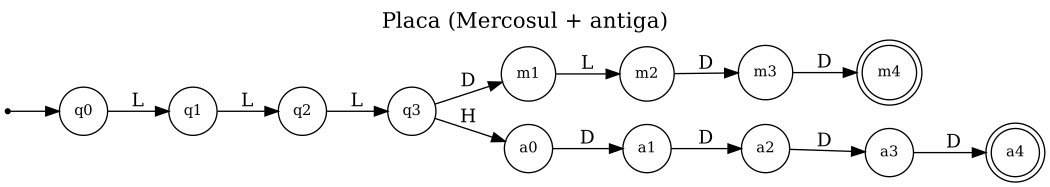

🖼️ Placa (Mercosul + antiga) (mínimo)  →  docs/placa_minimo.png


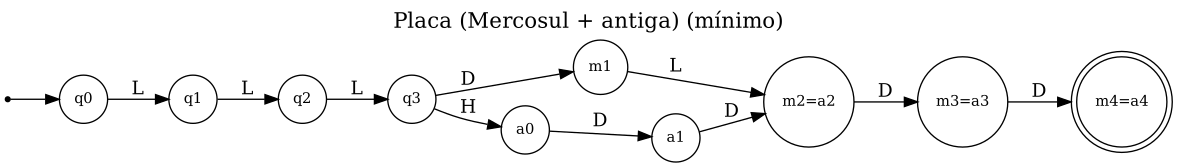

🖼️ Horário HH:MM  →  docs/hora.png


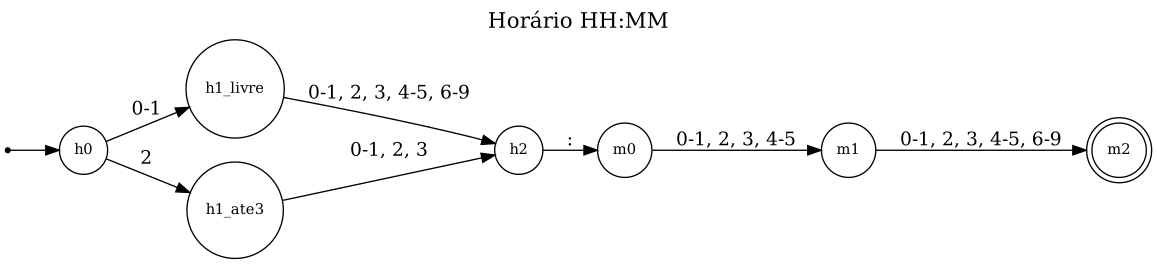

🖼️ Cancela  →  docs/cancela.png


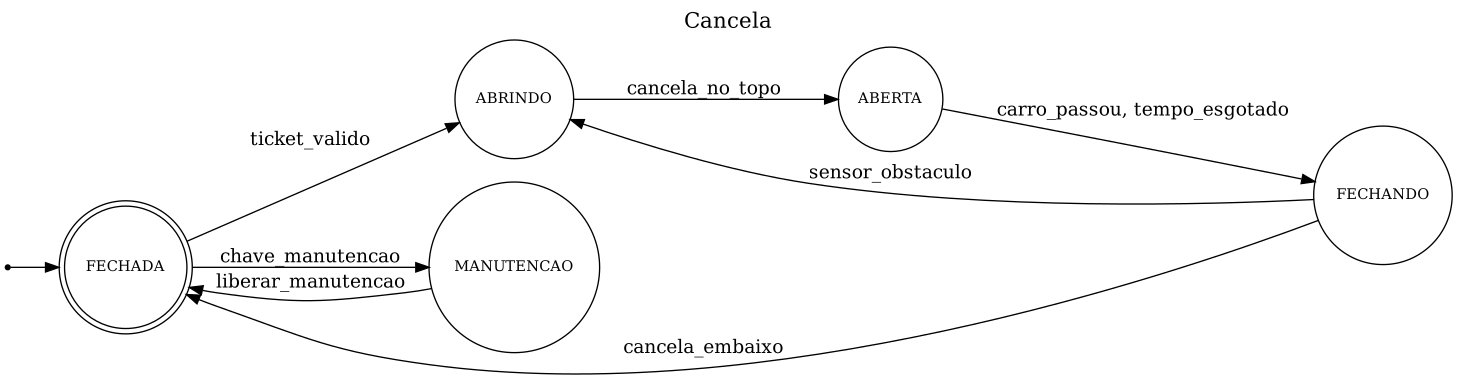

In [18]:
# ⭐ CÉLULA 10 (Bônus) — Desenho automático com Graphviz, gerado do próprio delta
desenhos = [(placa, "docs/placa.png"), (placa_minimo, "docs/placa_minimo.png"),
            (hora, "docs/hora.png"), (cancela, "docs/cancela.png")]
for afd, arquivo in desenhos:
    caminho = desenhar(afd, arquivo)
    if caminho:
        print(f"🖼️ {afd.nome}  →  {caminho}")
        display(Image(filename=caminho))

In [19]:
# ⭐ CÉLULA 11 (Bônus) — Scanner por TABELA: um AFD combinado (delta) no lugar dos `while`s
# O mesmo reconhecimento, mas agora tudo vem de UMA tabela δ: (estado, classe de caractere) -> próximo.
def classe_char(c):
    if "A" <= c <= "Z":
        return "U"                       # maiúscula
    if "a" <= c <= "z":
        return "l"                       # minúscula
    if "0" <= c <= "9":
        return "D"
    if c == "_":
        return "_"
    if c in "-.:=<>#\n":
        return c                         # cada símbolo é a sua própria classe
    if c in " \t\r":
        return "esp"
    return "outro"


T = {}                                   # δ do scanner combinado
# --- do estado inicial ---
T[("INI", "U")] = "P1"
for ch in ["l", "_"]:
    T[("INI", ch)] = "ID"
T[("INI", "D")] = "D1"
T[("INI", "=")], T[("INI", "<")], T[("INI", ">")] = "EQ", "LT", "GT"
T[("INI", "esp")], T[("INI", "\n")], T[("INI", "#")] = "ESP", "NL", "COM"
# --- identificadores, placa Mercosul (P1..P7) e placa antiga (A0..A4) ---
for q in ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "ID"]:
    for ch in ["U", "l", "D", "_"]:
        T[(q, ch)] = "ID"                # por padrão continua sendo um ID
T[("P1", "U")], T[("P2", "U")] = "P2", "P3"          # LLL
T[("P3", "D")] = "P4"                                # LLLD
T[("P4", "U")], T[("P5", "D")], T[("P6", "D")] = "P5", "P6", "P7"   # LLLDLDD = placa Mercosul
T[("P3", "-")] = "A0"                                # LLL-
T[("A0", "D")], T[("A1", "D")], T[("A2", "D")], T[("A3", "D")] = "A1", "A2", "A3", "A4"   # LLL-DDDD
# --- números: inteiro, real e hora (HH:MM só com exatamente 2 dígitos antes dos ':') ---
T[("D1", "D")], T[("D2", "D")], T[("INT", "D")] = "D2", "INT", "INT"
for q in ["D1", "D2", "INT"]:
    T[(q, ".")] = "R0"
T[("R0", "D")], T[("REAL", "D")] = "REAL", "REAL"
T[("D2", ":")] = "T0"
T[("T0", "D")], T[("T1", "D")] = "T1", "T2"
# --- operadores ---
T[("EQ", "=")], T[("LT", "=")], T[("GT", "=")] = "EQ2", "LE", "GE"
# --- ignorados: espaços e comentários ---
T[("ESP", "esp")] = "ESP"
for ch in ["U", "l", "D", "_", "-", ".", ":", "=", "<", ">", "#", "esp", "outro"]:
    T[("COM", ch)] = "COM"               # o comentário vai até o '\n'

ACEITA = {"P1": "ID", "P2": "ID", "P3": "ID", "P4": "ID", "P5": "ID", "P6": "ID", "ID": "ID",
          "P7": "PLACA", "A4": "PLACA", "D1": "NUM_INT", "D2": "NUM_INT", "INT": "NUM_INT",
          "REAL": "NUM_REAL", "T2": "HORA", "EQ": "ATRIB", "EQ2": "IGUAL", "LT": "MENOR",
          "LE": "MENOR_IGUAL", "GT": "MAIOR", "GE": "MAIOR_IGUAL",
          "ESP": "IGNORAR", "NL": "IGNORAR", "COM": "IGNORAR"}


def escanear_por_tabela(fonte):
    tokens, erros = [], []
    i, linha, coluna, n = 0, 1, 1, len(fonte)
    while i < n:
        estado, j, ultimo = "INI", i, None
        while j < n:                                          # anda na tabela enquanto houver seta
            proximo = T.get((estado, classe_char(fonte[j])))
            if proximo is None:
                break
            estado, j = proximo, j + 1
            if estado in ACEITA:
                ultimo = (ACEITA[estado], j)                  # Maximal Munch: guarda o MAIOR lexema aceito
        if ultimo is None:                                    # nenhum prefixo é aceito: erro léxico
            c = fonte[i]
            erros.append((linha, coluna, c, DICAS.get(c, DICA_PADRAO)))
            i, coluna = i + 1, coluna + 1
            continue
        tipo, fim = ultimo                                    # volta para o fim do maior lexema aceito
        lexema = fonte[i:fim]
        if tipo == "ID" and lexema in PALAVRAS_RESERVADAS:
            tipo = "RESERVADA"
        if tipo != "IGNORAR":
            tokens.append((tipo, lexema, linha, coluna))
        for ch in lexema:                                     # atualiza linha/coluna
            if ch == "\n":
                linha, coluna = linha + 1, 1
            else:
                coluna += 1
        i = fim
    return tokens, erros


print(f"Scanner por tabela: {len({q for q, _ in T} | set(T.values()))} estados, {len(T)} transições, "
      f"{len(set(classe_char(chr(k)) for k in range(128)))} classes de caractere.")

# Conferência 1: o roteiro da Célula 7 dá exatamente o mesmo resultado nos dois scanners
igual = escanear(roteiro) == escanear_por_tabela(roteiro)
print(f"Roteiro da Célula 7: scanner com while == scanner por tabela? {igual}")

# Conferência 2 (teste diferencial): 5.000 programas aleatórios montados com pedaços da linguagem
import random
random.seed(2026)
PEDACOS = ["ENTRADA", "SAIDA", "VAGA", "PAGO", "TARIFA", "ALERTA", "OBSTACULO", "BRA2E19", "ABC-1234",
           "ABC", "-", "1234", "08:15", "8:15", "123:45", "12.50", "12.", ".5", "4,00", "=", "==", "<",
           "<=", ">", ">=", "12", "007", "LOTACAO", "a_1", "abc-1234", "ABCD-1234", "ABC-12345",
           " ", "  ", "\t", "\n", "# nota\n", "#", "@", "é", ".", ":", ",", "_", "BRA2E19x", "bra2e19"]
divergencias = 0
for _ in range(5000):
    texto = "".join(random.choice(PEDACOS) for _ in range(random.randint(1, 14)))
    if escanear(texto) != escanear_por_tabela(texto):
        divergencias += 1
print(f"Teste diferencial (5.000 programas aleatórios): {divergencias} divergências")

# Conferência 3: o scanner e o validador de placa concordam (toda placa aceita vira UM token PLACA)
conflitos = 0
for n in range(9):
    for tupla in product("A1-x", repeat=n):
        w = "".join(tupla)
        if placa.rodar(w, mostrar=False):
            toks, errs = escanear_por_tabela(w)
            conflitos += not (len(toks) == 1 and toks[0][0] == "PLACA" and not errs)
print(f"Validador de placa × scanner (todas as palavras de até 8 símbolos): {conflitos} conflitos")

Scanner por tabela: 31 estados, 75 transições, 14 classes de caractere.
Roteiro da Célula 7: scanner com while == scanner por tabela? True


Teste diferencial (5.000 programas aleatórios): 0 divergências


Validador de placa × scanner (todas as palavras de até 8 símbolos): 0 conflitos


In [20]:
# ⭐ CÉLULA 12 (Bônus) — Tudo conectado: roteiro → scanner → tokens → validadores → eventos da cancela
import operator

OPERADORES = {"==": operator.eq, "<": operator.lt, "<=": operator.le, ">": operator.gt, ">=": operator.ge}


def minutos(hhmm):
    h, m = hhmm.split(":")
    return int(h) * 60 + int(m)


class Estacionamento:
    def __init__(self, capacidade=4):
        self.capacidade = capacidade
        self.tarifa = 4.00                 # por hora (ou fração)
        self.dentro = {}                   # placa -> (hora_de_entrada, vaga)
        self.alertas = []                  # (operador, limite)
        self.estado_cancela = cancela.inicial

    # --- a cancela é a máquina de estados da Célula 5 ---
    def evento(self, ev):
        proximo = cancela.delta.get((self.estado_cancela, ev))
        if proximo is None:
            permitidos = [e for (q, e) in cancela.delta if q == self.estado_cancela]
            print(f"      ❌ cancela: evento {ev!r} não é permitido em {self.estado_cancela}. "
                  f"Permitidos: {permitidos}")
            return False
        self.estado_cancela = proximo
        return True

    def ciclo_cancela(self):
        caminho = [self.estado_cancela]
        for ev in ("ticket_valido", "cancela_no_topo", "carro_passou", "cancela_embaixo"):
            if not self.evento(ev):
                return False
            caminho.append(self.estado_cancela)
        print("      🚧 cancela: " + " → ".join(caminho))
        return True

    def lotacao(self):
        return 100 * len(self.dentro) / self.capacidade

    def conferir_alertas(self):
        for texto, op, limite in self.alertas:
            if OPERADORES[op](self.lotacao(), limite):
                print(f"      🚨 ALERTA: LOTACAO {op} {limite:g} (atual: {self.lotacao():g}%)")

    # --- comandos ---
    def entrada(self, placa_txt, hora_txt, vaga):
        if not placa.rodar(placa_txt, mostrar=False):
            return print(f"   ❌ placa inválida {placa_txt!r} (o AFD de placa recusou)")
        if not hora.rodar(hora_txt, mostrar=False):
            return print(f"   ❌ hora inválida {hora_txt!r}: o AFD de horário recusou (vai de 00:00 a 23:59)")
        if placa_txt in self.dentro:
            return print(f"   ❌ {placa_txt} já está dentro do estacionamento")
        if len(self.dentro) >= self.capacidade:
            return print("   ❌ estacionamento lotado")
        if vaga in [v for _, v in self.dentro.values()]:
            return print(f"   ❌ vaga {vaga} ocupada")
        if self.ciclo_cancela():
            self.dentro[placa_txt] = (hora_txt, vaga)
            print(f"   ✅ entrada de {placa_txt} às {hora_txt} na vaga {vaga} (lotação {self.lotacao():g}%)")
            self.conferir_alertas()

    def saida(self, placa_txt, hora_txt, pago):
        if not hora.rodar(hora_txt, mostrar=False):
            return print(f"   ❌ hora inválida {hora_txt!r}: o AFD de horário recusou (vai de 00:00 a 23:59)")
        if placa_txt not in self.dentro:
            return print(f"   ❌ {placa_txt} não está no estacionamento")
        entrada_txt, vaga = self.dentro[placa_txt]
        permanencia = minutos(hora_txt) - minutos(entrada_txt)
        if permanencia < 0:
            return print("   ❌ a saída é anterior à entrada")
        horas = max(1, -(-permanencia // 60))                 # cobra por hora iniciada
        devido = horas * self.tarifa
        if round(pago * 100) < round(devido * 100):
            return print(f"   ❌ pagamento insuficiente: {permanencia} min = {horas} h × {self.tarifa:.2f} "
                         f"= {devido:.2f}, pago {pago:.2f}")
        if self.ciclo_cancela():
            del self.dentro[placa_txt]
            print(f"   ✅ saída de {placa_txt}: {permanencia} min = {horas} h × {self.tarifa:.2f} "
                  f"= {devido:.2f} (pago {pago:.2f})")
            self.conferir_alertas()

    def comando(self, lin, toks):
        # Cada comando vira uma "forma": RESERVADA vira o próprio texto; números e operadores viram NUM / OP
        forma = tuple(t[1] if t[0] == "RESERVADA"
                      else "NUM" if t[0] in ("NUM_INT", "NUM_REAL")
                      else "OP" if t[0] in ("IGUAL", "MENOR", "MENOR_IGUAL", "MAIOR", "MAIOR_IGUAL")
                      else t[0] for t in toks)
        lex = [t[1] for t in toks]
        print(f"▶ linha {lin}: {' '.join(lex)}")
        if forma == ("TARIFA", "ATRIB", "NUM"):
            self.tarifa = float(lex[2])
            print(f"   💲 tarifa = {self.tarifa:.2f} por hora")
        elif forma == ("ALERTA", "ID", "OP", "NUM") and lex[1] == "LOTACAO":
            self.alertas.append((lex[1], lex[2], float(lex[3])))
            print(f"   🔔 alerta registrado: LOTACAO {lex[2]} {lex[3]}")
        elif forma == ("ENTRADA", "PLACA", "HORA", "VAGA", "ID"):
            self.entrada(lex[1], lex[2], lex[4])
        elif forma == ("SAIDA", "PLACA", "HORA", "PAGO", "NUM"):
            self.saida(lex[1], lex[2], float(lex[4]))
        elif forma == ("OBSTACULO",):
            if self.evento("sensor_obstaculo"):
                print(f"   🚧 cancela agora em {self.estado_cancela}")
        else:
            print(f"   ❌ comando mal formado (sequência de tokens: {' '.join(forma)})")

    def executar(self, fonte):
        tokens_e, erros_e = escanear(fonte)
        print(f"📜 Scanner: {len(tokens_e)} tokens e {len(erros_e)} erro(s) léxico(s)")
        for lin, col, c, dica in erros_e:
            print(f"   ⚠️ linha {lin}, coluna {col}: {c!r} ({dica})")
        por_linha = {}
        for t in tokens_e:
            por_linha.setdefault(t[2], []).append(t)
        print()
        for lin in sorted(por_linha):
            self.comando(lin, por_linha[lin])
        print(f"\n📊 No fim do dia: dentro = {sorted(self.dentro)} · cancela = {self.estado_cancela}")


roteiro_do_dia = """# roteiro do dia (capacidade: 4 vagas)
TARIFA = 4.00
ALERTA LOTACAO >= 50
ENTRADA BRA2E19 08:15 VAGA A12
ENTRADA ABC-1234 08:20 VAGA B7
SAIDA BRA2E19 10:40 PAGO 12.00
ENTRADA XYZ9A00 25:99 VAGA C3
SAIDA ABC-1234 09:00 PAGO 1.00
OBSTACULO
SAIDA ABC-1234 09:10 PAGO 4,00
"""
Estacionamento(capacidade=4).executar(roteiro_do_dia)

📜 Scanner: 39 tokens e 1 erro(s) léxico(s)
   ⚠️ linha 10, coluna 28: ',' (use ponto como separador decimal (ex.: 12.50))

▶ linha 2: TARIFA = 4.00
   💲 tarifa = 4.00 por hora
▶ linha 3: ALERTA LOTACAO >= 50
   🔔 alerta registrado: LOTACAO >= 50
▶ linha 4: ENTRADA BRA2E19 08:15 VAGA A12
      🚧 cancela: FECHADA → ABRINDO → ABERTA → FECHANDO → FECHADA
   ✅ entrada de BRA2E19 às 08:15 na vaga A12 (lotação 25%)
▶ linha 5: ENTRADA ABC-1234 08:20 VAGA B7
      🚧 cancela: FECHADA → ABRINDO → ABERTA → FECHANDO → FECHADA
   ✅ entrada de ABC-1234 às 08:20 na vaga B7 (lotação 50%)
      🚨 ALERTA: LOTACAO >= 50 (atual: 50%)
▶ linha 6: SAIDA BRA2E19 10:40 PAGO 12.00
      🚧 cancela: FECHADA → ABRINDO → ABERTA → FECHANDO → FECHADA
   ✅ saída de BRA2E19: 145 min = 3 h × 4.00 = 12.00 (pago 12.00)
▶ linha 7: ENTRADA XYZ9A00 25:99 VAGA C3
   ❌ hora inválida '25:99': o AFD de horário recusou (vai de 00:00 a 23:59)
▶ linha 8: SAIDA ABC-1234 09:00 PAGO 1.00
   ❌ pagamento insuficiente: 40 min = 1 h × 4.00

In [21]:
# ✅ CÉLULA 13 — Autoavaliação: confere os requisitos R1 a R6 por código
def conferir(codigo, condicao, descricao):
    print(("✅" if condicao else "❌"), codigo, "—", descricao)
    assert condicao, f"{codigo} falhou: {descricao}"


digitos_finos = [s for s in hora.alfabeto if s != ":"]
conferir("R1", len(placa.estados) >= 5 and len(hora.estados) >= 5,
         f"2 validadores com ≥ 5 estados ({len(placa.estados)} e {len(hora.estados)})")
conferir("R1", len(digitos_finos) >= 4, f"classes finas de dígitos no horário: {digitos_finos}")
conferir("R2", placa.rodar("ABC-1234", False) and not placa.rodar("BRA2019", False)
         and hora.rodar("23:59", False) and not hora.rodar("24:00", False),
         "rodar() com 1 palavra aceita e 1 rejeitada em cada AFD")
for nome, (aceitas, rejeitadas, div), lista in [("placa", res_placa, PALAVRAS_PLACA),
                                                 ("horário", res_hora, PALAVRAS_HORA)]:
    conferir("R3", aceitas >= 5 and rejeitadas >= 5 and "" in lista and div == 0,
             f"{nome}: {aceitas} aceitas, {rejeitadas} rejeitadas, palavra vazia testada, {div} divergências")
conferir("R4", len(cancela.estados) >= 5 and len(cancela.delta) >= 6,
         f"cancela com {len(cancela.estados)} estados e {len(cancela.delta)} transições")
conferir("R5", len(TIPOS_TOKEN) >= 8 and len(PALAVRAS_RESERVADAS) >= 3,
         f"scanner com {len(TIPOS_TOKEN)} tipos de token e {len(PALAVRAS_RESERVADAS)} palavras reservadas")
conferir("R5", [t[0] for t in escanear("== =")[0]] == ["IGUAL", "ATRIB"],
         "Maximal Munch: '==' é um token só e '=' sozinho é outro")
conferir("R5", len(escanear(roteiro)[1]) == 3 and len(escanear(roteiro)[0]) > 20,
         "erros com linha, coluna e dica — e o scanner continua depois de cada erro")
conferir("R5", len(DICAS) >= 2, f"{len(DICAS)} dicas específicas do domínio")
conferir("R6", widgets is not None and painel is not None, "painel ipywidgets montado (validadores, scanner e cancela)")
print("\n📄 R7: o README.md (nomes, desenhos, tabela de tokens, como rodar e exemplos de saída) está no repositório.")
print("🎉 Todos os requisitos conferidos!")

✅ R1 — 2 validadores com ≥ 5 estados (13 e 7)
✅ R1 — classes finas de dígitos no horário: ['0-1', '2', '3', '4-5', '6-9']
✅ R2 — rodar() com 1 palavra aceita e 1 rejeitada em cada AFD
✅ R3 — placa: 7 aceitas, 12 rejeitadas, palavra vazia testada, 0 divergências
✅ R3 — horário: 7 aceitas, 13 rejeitadas, palavra vazia testada, 0 divergências
✅ R4 — cancela com 5 estados e 8 transições
✅ R5 — scanner com 12 tipos de token e 7 palavras reservadas
✅ R5 — Maximal Munch: '==' é um token só e '=' sozinho é outro
✅ R5 — erros com linha, coluna e dica — e o scanner continua depois de cada erro
✅ R5 — 4 dicas específicas do domínio
✅ R6 — painel ipywidgets montado (validadores, scanner e cancela)

📄 R7: o README.md (nomes, desenhos, tabela de tokens, como rodar e exemplos de saída) está no repositório.
🎉 Todos os requisitos conferidos!
